In [ ]:
#GitHub Link: https://github.com/eliascari/US-Employment-Data-Analysis-CA1-EliasCari-2023275
#Video Presentation Link: https://drive.google.com/file/d/1nOPSBlxdEMtMQ2hMyrkr0UZj6qX4b54X/view?usp=drive_link

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
file_path ="all_data_M_2023.xlsx"
df = pd.read_excel(file_path, sheet_name = "All May 2023 data")
df.head()

,AREA,AREA_TITLE,AREA_TYPE,PRIM_STATE,NAICS,NAICS_TITLE,I_GROUP,OWN_CODE,OCC_CODE,OCC_TITLE,...,H_MEDIAN,H_PCT75,H_PCT90,A_PCT10,A_PCT25,A_MEDIAN,A_PCT75,A_PCT90,ANNUAL,HOURLY
0,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,00-0000,All Occupations,...,23.11,37.01,58.4,29050,35660,48060,76980,121470,NaN,NaN
1,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-0000,Management Occupations,...,56.19,81.29,111.36,54550,78330,116880,169090,231620,NaN,NaN
2,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1000,Top Executives,...,49.74,79.57,#,46400,66170,103460,165500,#,NaN,NaN
3,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1010,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN
4,99,U.S.,1,US,000000,Cross-industry,cross-industry,1235,11-1011,Chief Executives,...,99.37,#,#,80000,130840,206680,#,#,NaN,NaN


In [3]:
print(df.shape)

(413327, 32)


In [4]:
print(df.columns.tolist())

['AREA', 'AREA_TITLE', 'AREA_TYPE', 'PRIM_STATE', 'NAICS', 'NAICS_TITLE', 'I_GROUP', 'OWN_CODE', 'OCC_CODE', 'OCC_TITLE', 'O_GROUP', 'TOT_EMP', 'EMP_PRSE', 'JOBS_1000', 'LOC_QUOTIENT', 'PCT_TOTAL', 'PCT_RPT', 'H_MEAN', 'A_MEAN', 'MEAN_PRSE', 'H_PCT10', 'H_PCT25', 'H_MEDIAN', 'H_PCT75', 'H_PCT90', 'A_PCT10', 'A_PCT25', 'A_MEDIAN', 'A_PCT75', 'A_PCT90', 'ANNUAL', 'HOURLY']


In [5]:
data_scientists = df[
    df["OCC_TITLE"].str.contains(
        "Data Scientist",
        case=False,
        na=False
    )
]

print("Matching records:", len(data_scientists))

display(
    data_scientists[
        ["AREA_TITLE", "AREA_TYPE", "NAICS",
         "OCC_TITLE", "TOT_EMP"]
    ].head(20)
)

Matching records: 940


,AREA_TITLE,AREA_TYPE,NAICS,OCC_TITLE,TOT_EMP
164,U.S.,1,000000,Data Scientists,192710
165,U.S.,1,000000,Data Scientists,192710
1562,U.S.,1,000001,Data Scientists,184720
1563,U.S.,1,000001,Data Scientists,184720
3222,U.S.,1,21,Data Scientists,360
3223,U.S.,1,21,Data Scientists,360
3750,U.S.,1,22,Data Scientists,810
3751,U.S.,1,22,Data Scientists,810
4278,U.S.,1,23,Data Scientists,440
4279,U.S.,1,23,Data Scientists,440


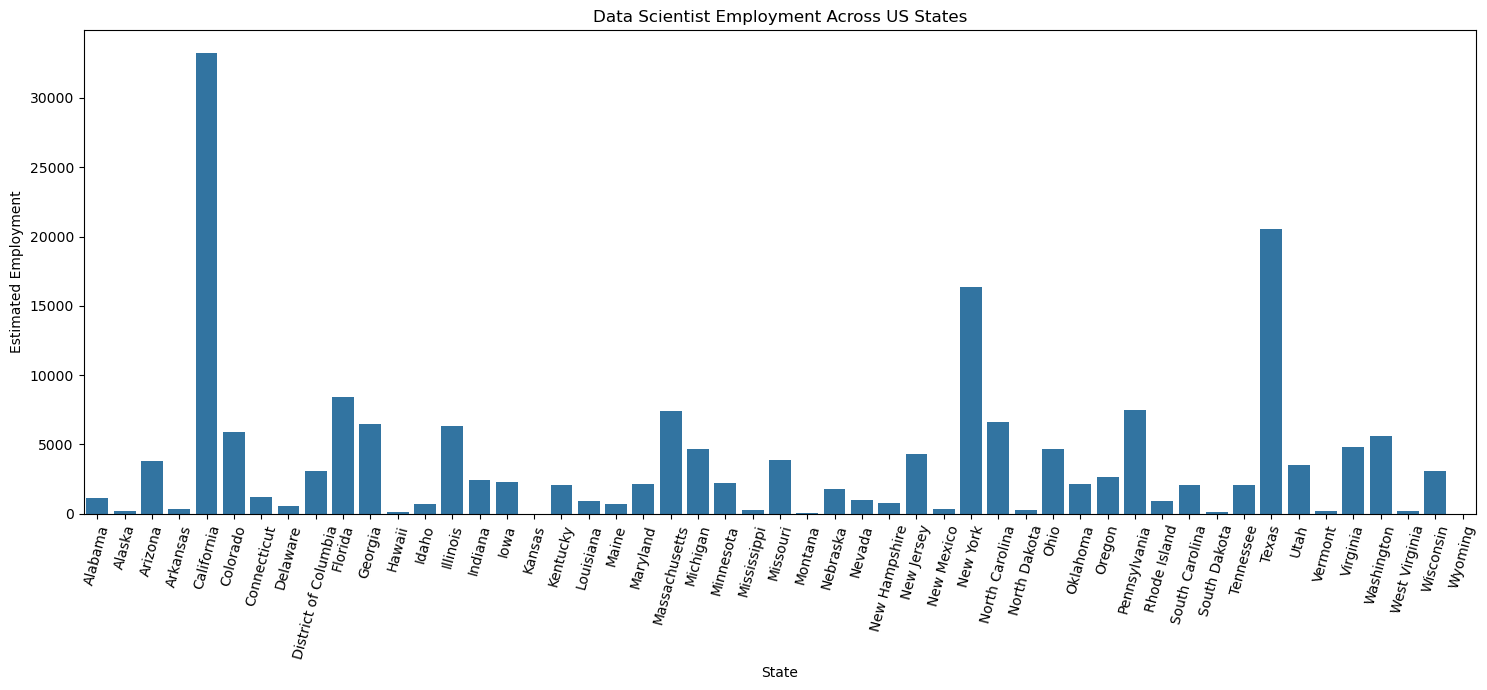

In [6]:
data_scientists = df[
    (df["OCC_TITLE"] == "Data Scientists") &
    (df["AREA_TYPE"].astype(str).str.strip() == "2") &
    (df["NAICS"].astype(str).str.strip().str.zfill(6) == "000000")
].copy()

data_scientists["TOT_EMP"] = pd.to_numeric(
    data_scientists["TOT_EMP"],
    errors="coerce"
)
plt.figure(figsize=(15, 7))

sns.barplot(
    data=data_scientists,
    x="AREA_TITLE",
    y="TOT_EMP"
)

plt.title("Data Scientist Employment Across US States")
plt.xlabel("State")
plt.ylabel("Estimated Employment")
plt.xticks(rotation=75)
plt.tight_layout()
plt.show()

In [13]:
scientists = df[
    (df["OCC_TITLE"] == "Data Scientists") &
    (df["AREA_TYPE"].astype(str).str.strip() == "2") &
    (df["NAICS"].astype(str).str.strip().str.zfill(6) == "000000")
].copy()

scientists["LOC_QUOTIENT"] = pd.to_numeric(
    scientists["LOC_QUOTIENT"],
    errors="coerce"
)

print("Number of states:", len(scientists))

Number of states: 51


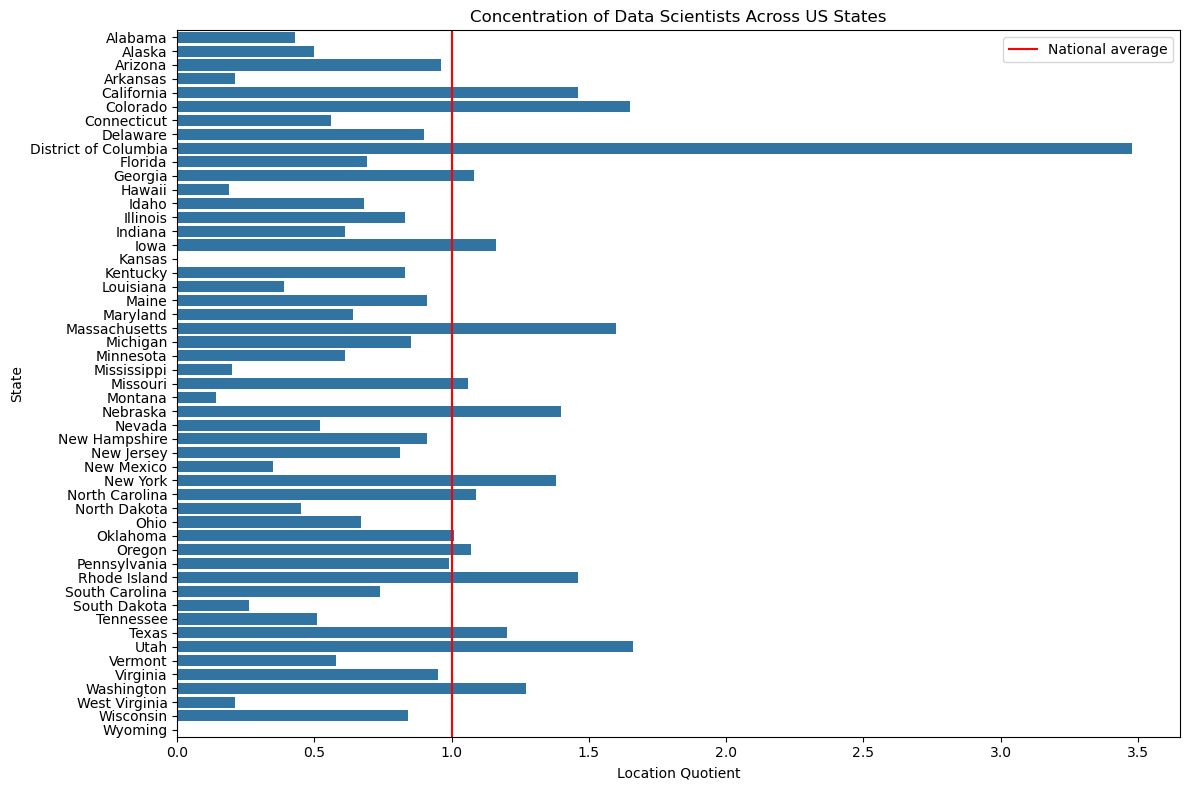

In [14]:
plt.figure(figsize=(12, 8))

sns.barplot(
    data=scientists,
    x="LOC_QUOTIENT",
    y="AREA_TITLE"
)

plt.axvline(
    x=1,
    color="red",
    linestyle="-",
    label="National average"
)

plt.title("Concentration of Data Scientists Across US States")
plt.xlabel("Location Quotient")
plt.ylabel("State")
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
scatter_data = df[
    (df["AREA_TYPE"].astype(str).str.strip() == "1") &
    (df["NAICS"].astype(str).str.strip().str.zfill(6) == "000000") &
    (df["O_GROUP"].astype(str).str.strip().str.lower() == "detailed")
].copy()

scatter_data["TOT_EMP"] = pd.to_numeric(
    scatter_data["TOT_EMP"], errors="coerce"
)

scatter_data["A_MEAN"] = pd.to_numeric(
    scatter_data["A_MEAN"], errors="coerce"
)

scatter_data = scatter_data[
    (scatter_data["TOT_EMP"] > 0) &
    (scatter_data["A_MEAN"] > 0)
]

print("Number of occupations:", len(scatter_data))

Number of occupations: 826


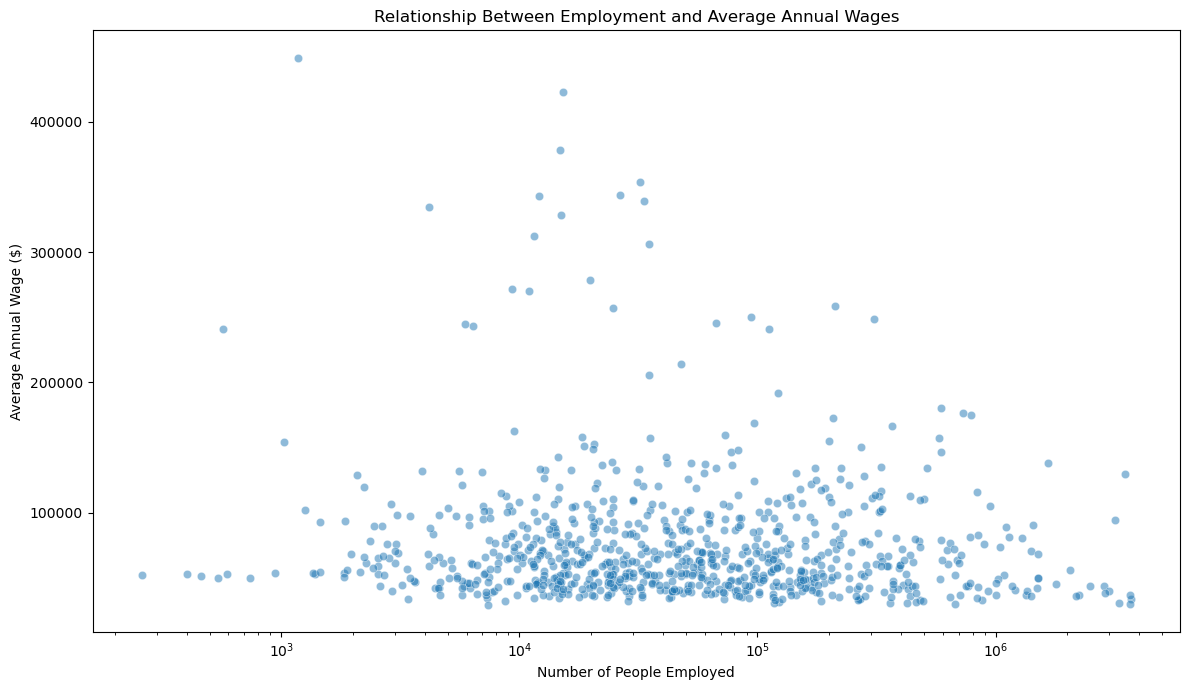

In [16]:
plt.figure(figsize=(12, 7))

sns.scatterplot(
    data=scatter_data,
    x="TOT_EMP",
    y="A_MEAN",
    alpha=0.5
)

plt.title("Relationship Between Employment and Average Annual Wages")
plt.xlabel("Number of People Employed")
plt.ylabel("Average Annual Wage ($)")

plt.xscale("log")

plt.tight_layout()
plt.show()

In [43]:
correlation = scatter_data["TOT_EMP"].corr(
    scatter_data["A_MEAN"]
)

print("Correlation", round(correlation, 3))

Correlation -0.085


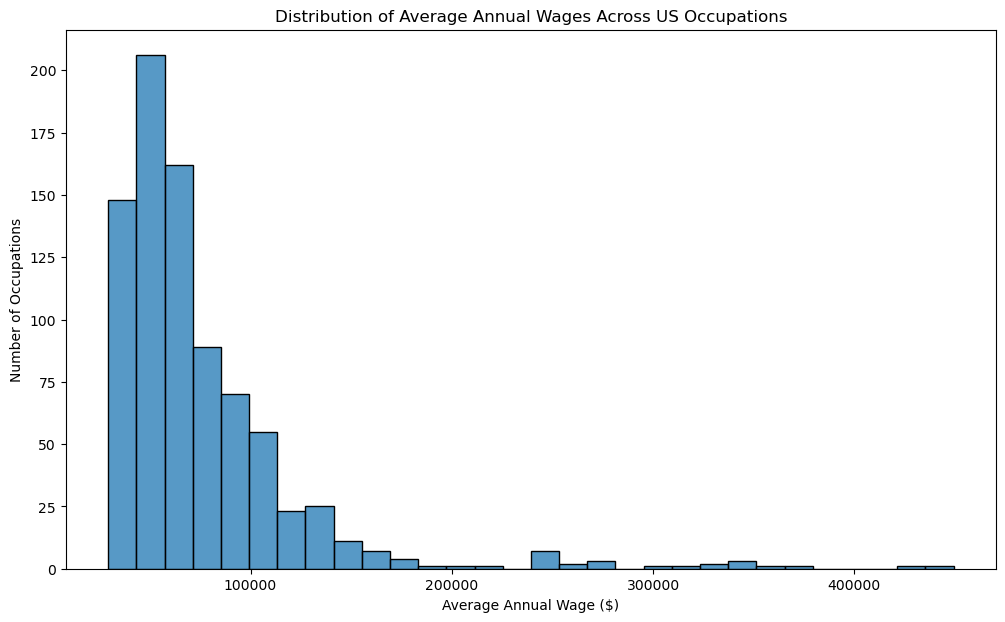

In [46]:
plt.figure(figsize=(12, 7))

sns.histplot(
    data=scatter_data,
    x="A_MEAN",
    bins=30,
)

plt.title("Distribution of Average Annual Wages Across US Occupations")
plt.xlabel("Average Annual Wage ($)")
plt.ylabel("Number of Occupations")

plt.show()

In [44]:
top_15 = scatter_data.sort_values(
    by="TOT_EMP",
    ascending=False
).head(15)

display(
    top_15[["OCC_TITLE", "TOT_EMP", "A_MEAN"]]
)

,OCC_TITLE,TOT_EMP,A_MEAN
613,Home Health and Personal Care Aides,3689350,33380.0
804,Retail Salespersons,3684740,36690.0
699,Fast Food and Counter Workers,3676580,30110.0
6,General and Operations Managers,3507810,129330.0
798,Cashiers,3298660,30710.0
540,Registered Nurses,3175390,94480.0
1389,"Laborers and Freight, Stock, and Material Move...",3008300,39760.0
1392,Stockers and Order Fillers,2872680,37990.0
872,Customer Service Representatives,2858710,43520.0
934,"Office Clerks, General",2496370,43560.0


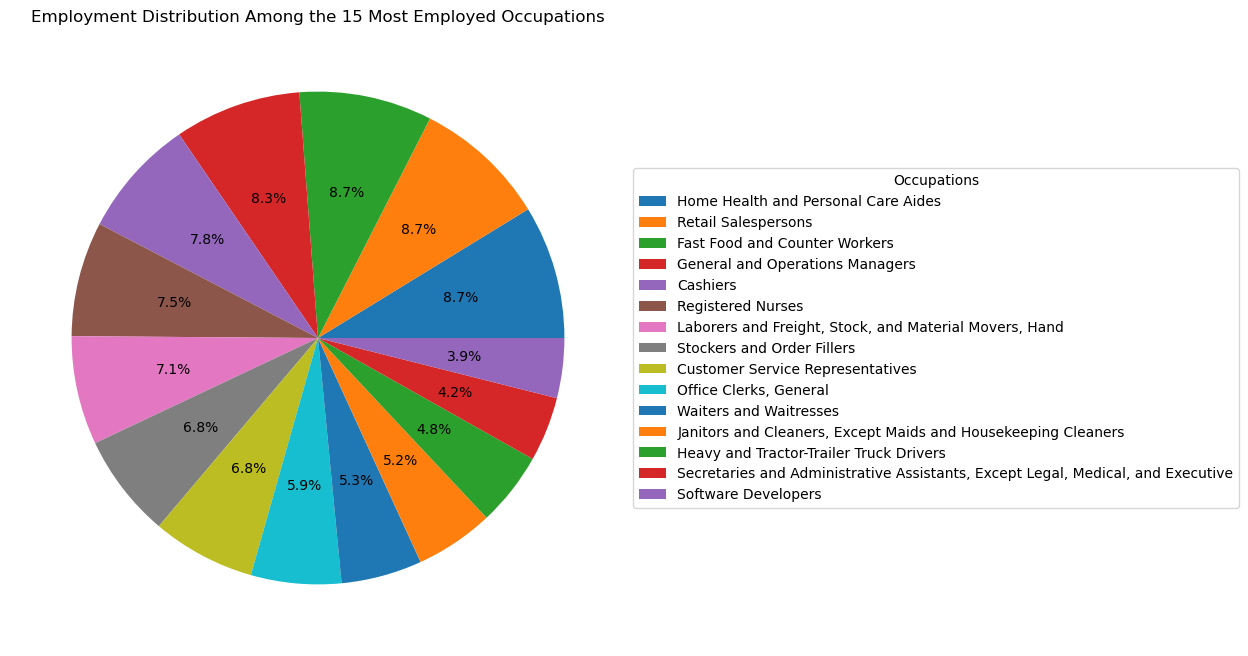

In [45]:
plt.figure(figsize=(12, 8))

plt.pie(
    top_15["TOT_EMP"],
    autopct="%1.1f%%",
)

plt.title("Employment Distribution Among the 15 Most Employed Occupations")

plt.legend(
    top_15["OCC_TITLE"],
    title="Occupations",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

plt.show()